# LeetCode #380: Insert Delete GetRandom O(1)

https://leetcode.com/problems/insert-delete-getrandom-o1/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **HashSet Only** | Insert/Delete $O(1)$, GetRandom $O(n)$ | $O(n)$ |
| **Optimal: HashMap + Dynamic Array ★** | Insert/Delete/GetRandom all $O(1)$ | $O(n)$ |

---

## Understanding the Methods

### HashSet Only
A HashSet supports O(1) insert and delete, but getRandom requires converting to an array or list first, which takes O(n) time.

### Optimal: HashMap + Dynamic Array ★
Maintain a dynamic array (list) for O(1) random access and a hash map from value to its index in the array. Insert appends to the array. Delete swaps the target with the last element, updates the map, then removes the last element. GetRandom picks a random index.

**Why this is better than HashSet Only:** The swap-with-last trick enables true O(1) deletion from the array while preserving O(1) random access for getRandom.

**Constraints:**
* -2^31 <= val <= 2^31 - 1
* At most 2 * 10^5 calls to insert, remove, and getRandom
* There will be at least one element when getRandom is called

## Solutions

### C#

In [ ]:
public class RandomizedSet {
    private List<int> nums;
    private Dictionary<int, int> valToIdx;
    private Random rand;

    public RandomizedSet() {
        nums = new List<int>();
        valToIdx = new Dictionary<int, int>();
        rand = new Random();
    }

    public bool Insert(int val) {
        if (valToIdx.ContainsKey(val)) return false;
        valToIdx[val] = nums.Count;
        nums.Add(val);
        return true;
    }

    public bool Remove(int val) {
        if (!valToIdx.ContainsKey(val)) return false;
        int idx = valToIdx[val];
        int last = nums[nums.Count - 1];
        nums[idx] = last;
        valToIdx[last] = idx;
        nums.RemoveAt(nums.Count - 1);
        valToIdx.Remove(val);
        return true;
    }

    public int GetRandom() {
        return nums[rand.Next(nums.Count)];
    }
}

### Python

In [ ]:
import random

class RandomizedSet:
    def __init__(self):
        self.nums = []
        self.val_to_idx = {}

    def insert(self, val: int) -> bool:
        if val in self.val_to_idx:
            return False
        self.val_to_idx[val] = len(self.nums)
        self.nums.append(val)
        return True

    def remove(self, val: int) -> bool:
        if val not in self.val_to_idx:
            return False
        idx = self.val_to_idx[val]
        last = self.nums[-1]
        self.nums[idx] = last
        self.val_to_idx[last] = idx
        self.nums.pop()
        del self.val_to_idx[val]
        return True

    def getRandom(self) -> int:
        return random.choice(self.nums)

### Go

In [ ]:
import "math/rand"

type RandomizedSet struct {
    nums     []int
    valToIdx map[int]int
}

func Constructor() RandomizedSet {
    return RandomizedSet{nums: []int{}, valToIdx: map[int]int{}}
}

func (rs *RandomizedSet) Insert(val int) bool {
    if _, ok := rs.valToIdx[val]; ok {
        return false
    }
    rs.valToIdx[val] = len(rs.nums)
    rs.nums = append(rs.nums, val)
    return true
}

func (rs *RandomizedSet) Remove(val int) bool {
    idx, ok := rs.valToIdx[val]
    if !ok {
        return false
    }
    last := rs.nums[len(rs.nums)-1]
    rs.nums[idx] = last
    rs.valToIdx[last] = idx
    rs.nums = rs.nums[:len(rs.nums)-1]
    delete(rs.valToIdx, val)
    return true
}

func (rs *RandomizedSet) GetRandom() int {
    return rs.nums[rand.Intn(len(rs.nums))]
}

### Rust

In [ ]:
use std::collections::HashMap;
use rand::Rng;

struct RandomizedSet {
    nums: Vec<i32>,
    val_to_idx: HashMap<i32, usize>,
}

impl RandomizedSet {
    fn new() -> Self {
        RandomizedSet { nums: Vec::new(), val_to_idx: HashMap::new() }
    }

    fn insert(&mut self, val: i32) -> bool {
        if self.val_to_idx.contains_key(&val) { return false; }
        self.val_to_idx.insert(val, self.nums.len());
        self.nums.push(val);
        true
    }

    fn remove(&mut self, val: i32) -> bool {
        if let Some(&idx) = self.val_to_idx.get(&val) {
            let last = *self.nums.last().unwrap();
            self.nums[idx] = last;
            self.val_to_idx.insert(last, idx);
            self.nums.pop();
            self.val_to_idx.remove(&val);
            true
        } else {
            false
        }
    }

    fn get_random(&self) -> i32 {
        let idx = rand::thread_rng().gen_range(0..self.nums.len());
        self.nums[idx]
    }
}

## Example Scenarios

### 1. Common Case — Insert, Delete, GetRandom
**Input:** `insert(1), insert(2), insert(3), remove(2), getRandom()`
Two structures work together: a dynamic array `a` (O(1) append and O(1) random access by index) and a hash map `val -> index` (O(1) membership and location). After the ops the array is `[1,3]` and the map is `{1:0, 3:1}`; `getRandom` returns `a[rand(len)]` uniformly. **Output:** every op is $O(1)$.

### 2. Slightly Complex — The Swap-With-Last Delete Trick
**Input:** `insert 10,20,30,40 ; remove(20)`
Deleting from the middle of an array is normally $O(n)$ because of shifting. Instead, copy the **last** element into the slot being removed, update that element's index in the map, then `pop()` the tail. Array `[10,20,30,40]` becomes `[10,40,30]`, map `{10:0, 40:1, 30:2}`. Order is not preserved — irrelevant for a set that only needs membership and uniform random. **Output:** `remove` is $O(1)$.

### 3. Edge Case: Time Factor — Every Operation Stays O(1)
**Input:** `insert(5), insert(7), getRandom(), remove(5), getRandom()`
No linear scan, no shifting: `insert` appends, `remove` swaps-and-pops, `getRandom` indexes `a[rand]`. All three are $O(1)$. **Output:** `[7]` remains.

### 4. Edge Case: Space Factor — Empty Set, Absent Removes
**Input:** `remove(9), insert(1), remove(1), remove(1)`
`remove` on a value that was never inserted returns `false` in $O(1)$; the array and map just stay empty. No extra allocation beyond the stored elements. **Output:** `false, true, true, false`.

### 5. Almost-Impossible but Plausible — Remove the Tail / Last Item
**Input:** `insert(8), insert(9), remove(9), remove(8)`
When the removed value **is** the last element, the swap is a no-op and popping alone suffices. Removing the only remaining element empties both structures cleanly. **Output:** both structures empty.


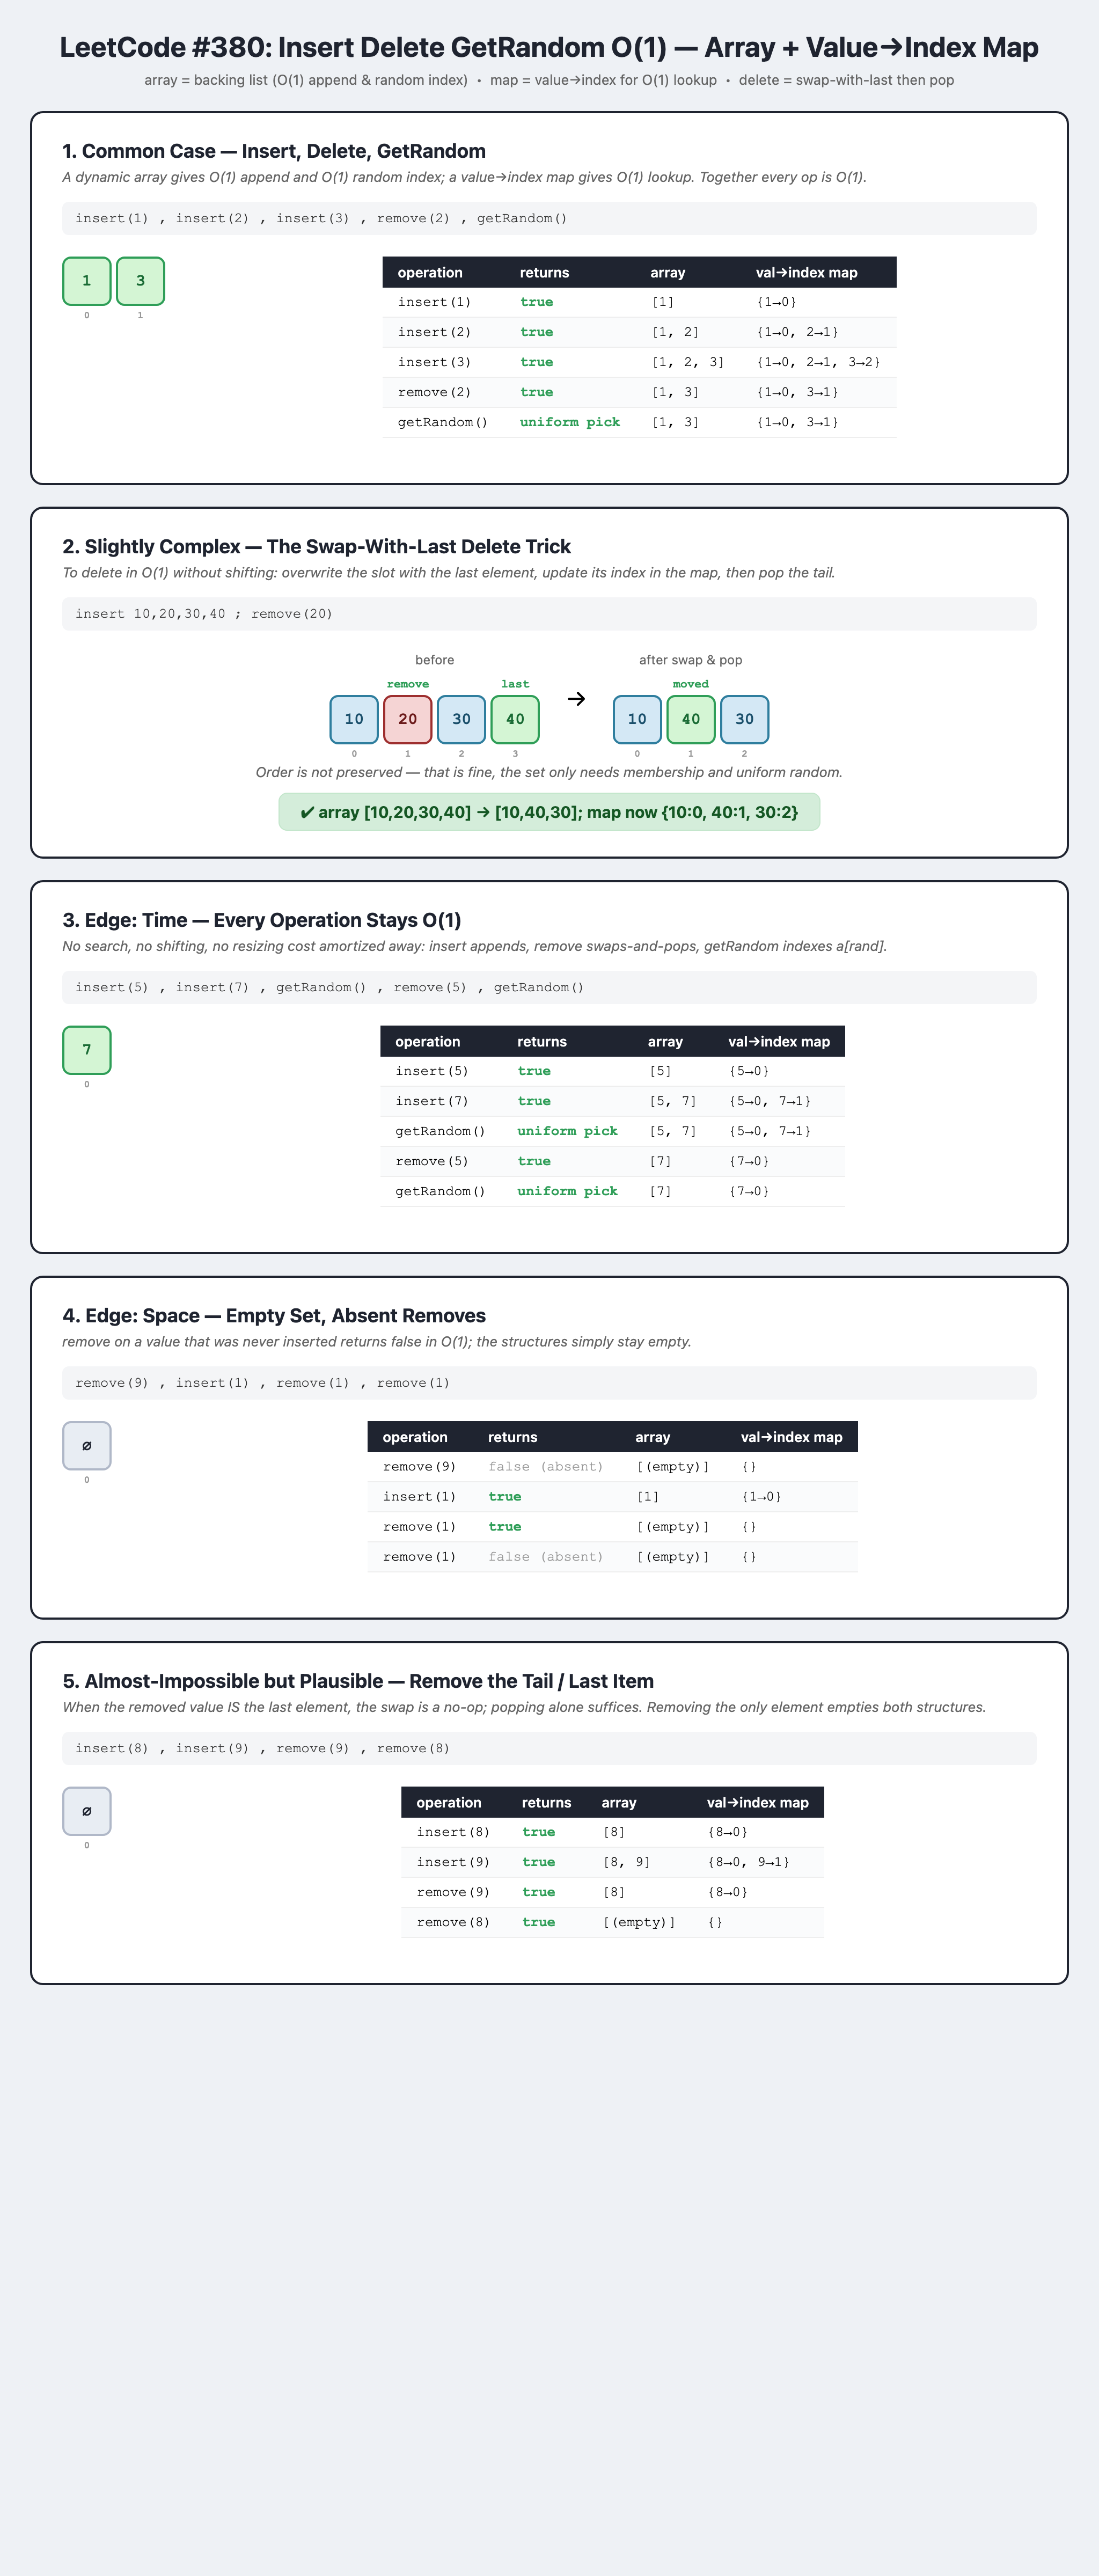